# Renk Maskesi Kutu Değerlendirmesi — TP / FP / FN

**Üye:** Murathan  |  **Branch:** `feat/detector-evaluation`  |  **Deney kimliği:** `color_mask_box_eval`

Bu defter, RGB ve HSV renk maskelerinden üretilen aday kutuları elle çizilmiş gerçek baret kutularıyla karşılaştırır ve kutu düzeyinde **TP / FP / FN** sayar (Hedef 3).

- **Hazır dedektör kullanılmamıştır.** Yönergenin 6. maddesi isteğe bağlıdır; buradaki sonuç bir YOLO/dedektör sonucu değil, *renk maskesi kutu değerlendirmesi*dir.
- Kutu = "sarı renkli bağlı bölge". Kutunun bulunması baretin **başta** olduğunu göstermez; dört sınıflı karar ayrı tutulur.
- Confidence değeri yoktur; sonuçlar yalnızca sayımdır.

## 1. Ortam ve ortak veri

In [1]:
from pathlib import Path
import sys, json

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src" / "common.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Notebook'u klonlanan depo içinden açın.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import pandas as pd

from src.common import load_config, load_dataset, load_image
from src.detection import predict_boxes, draw_boxes
from src.metrics import evaluate_boxes, iou

records = load_dataset()
print(f"Kaynak listesinde {len(records)} görüntü var:",
      ", ".join(f"{r['image_id']} ({r['split']})" for r in records))

Kaynak listesinde 6 görüntü var: G1 (development), G2 (development), K1 (control), K2 (control), K3 (control), K4 (control)


## 2. Dondurulmuş ayarlar

Renk aralıkları ekibin G1/G2 üzerinde dondurduğu ortak RGB/HSV ayarlarıdır. Kutu kuralının iki parametresi (3×3 açma/kapama, en küçük bileşen 50 piksel) yalnızca G1/G2'de seçilmiş ve K1–K4 çalıştırılmadan önce dondurulmuştur.

In [2]:
settings = load_config("detector_config.json")
box_config = settings["mask_box"]
color_configs = {"rgb": load_config("rgb_config.json"), "hsv": load_config("hsv_config.json")}
IOU_THRESHOLD = settings["evaluation_iou_threshold"]

print("Hazır dedektör:", settings["status"])
print("Kutu kuralı   :", {k: box_config[k] for k in ("morph_kernel_size", "min_component_area_px", "frozen")})
print("Değerlendirme : IoU >=", IOU_THRESHOLD, "(bire bir eşleştirme)")
for name, cfg in color_configs.items():
    print(f"{name.upper():4s} aralığı  : {cfg['lower']} - {cfg['upper']}  (frozen={cfg['frozen']})")

Hazır dedektör: not_used
Kutu kuralı   : {'morph_kernel_size': 3, 'min_component_area_px': 50, 'frozen': True}
Değerlendirme : IoU >= 0.5 (bire bir eşleştirme)
RGB  aralığı  : [180, 140, 0] - [255, 255, 120]  (frozen=True)
HSV  aralığı  : [18, 80, 80] - [50, 255, 255]  (frozen=True)


## 3. Deney öncesi tahmin

Kontrol görüntüleri çalıştırılmadan önce `docs/predictions.csv` içine kaydedilmiştir; sonuç görüldükten sonra değiştirilmemiştir.

In [3]:
predictions = pd.read_csv(ROOT / "docs/predictions.csv")
row = predictions[predictions.experiment_id == "color_mask_box_eval"].iloc[0]
print("1)", row.prediction_sentence_1)
print("2)", row.prediction_sentence_2)

1) Renk maskesinden çıkan kutuların baret dışı sarı nesneler (yelek, ekipman) yüzünden özellikle RGB'de çok sayıda FP üreteceğini, K4'te elde tutulan bareti ise TP olarak bulacağını ama bunun baretin başta olduğunu göstermeyeceğini bekliyorum.
2) K2'deki karanlık baretin renk aralığının dışında kalıp FN olacağını, K3'teki uzak ve küçük baretlerin de maskede parçalı ve küçük kalacağı için IoU>=0.50'yi sağlayamayıp FN olacağını bekliyorum.


## 4. Ölçüm fonksiyonunun kısa kontrolü

`iou` ve `evaluate_boxes` fonksiyonları `tests/test_metrics.py` ile test edilmiştir. Burada K2'nin gerçek baret kutusu üzerinde kuralın nasıl çalıştığı görülür: aynı barete iki kutu düşerse yalnızca biri TP sayılır.

In [4]:
k2_gt = [981, 94, 1070, 165]
example = evaluate_boxes([{"box": k2_gt}, {"box": [985, 97, 1072, 168]}, {"box": [10, 10, 60, 60]}], [k2_gt])
print("IoU(kendisi) =", iou(k2_gt, k2_gt))
print("TP/FP/FN     =", example["tp"], example["fp"], example["fn"])

IoU(kendisi) = 1.0
TP/FP/FN     = 1 2 0


## 5. Geliştirme kontrolü (G1, G2) — yalnızca ayar seçimi için

In [5]:
def evaluate(split):
    rows, store = [], {}
    for rec in load_dataset(split):
        image = load_image(rec["relative_path"])
        for method, cfg in color_configs.items():
            _, comps = predict_boxes(image, cfg, box_config)
            ev = evaluate_boxes([{"box": c["box"]} for c in comps], rec["helmet_boxes"], IOU_THRESHOLD)
            rows.append({"Görüntü": rec["image_id"], "Yöntem": method.upper(), "Koşul": rec["condition"],
                         "Doğru sınıf": rec["ground_truth_class"], "GT kutu": len(rec["helmet_boxes"]),
                         "Maske kutusu": len(comps), "TP": ev["tp"], "FP": ev["fp"], "FN": ev["fn"],
                         "Eşleşen IoU": ", ".join(f"{m['iou']:.2f}" for m in ev["matches"]) or "-"})
            store[(rec["image_id"], method)] = (image, comps, rec, ev)
    return pd.DataFrame(rows), store

dev_table, _ = evaluate("development")
dev_table

,Görüntü,Yöntem,Koşul,Doğru sınıf,GT kutu,Maske kutusu,TP,FP,FN,Eşleşen IoU
0,G1,RGB,daylight_site_yellow_equipment_distractor,no_helmet,0,2,0,2,0,-
1,G1,HSV,daylight_site_yellow_equipment_distractor,no_helmet,0,3,0,3,0,-
2,G2,RGB,bright_studio_like,helmet_on_head,1,21,1,20,0,0.54
3,G2,HSV,bright_studio_like,helmet_on_head,1,5,1,4,0,0.66


## 6. Kontrol sonucu (K1–K4)

Aynı dondurulmuş ayarlarla tek çalıştırma. Kalıcı çıktılar `python scripts/evaluate_color_mask_boxes.py` ile üretilir: `results/detector/detection_results.csv`, `raw_mask_boxes.json` ve görseller.

In [6]:
control_table, control_store = evaluate("control")
control_table

,Görüntü,Yöntem,Koşul,Doğru sınıf,GT kutu,Maske kutusu,TP,FP,FN,Eşleşen IoU
0,K1,RGB,daylight_site_head_cropped,uncertain,0,0,0,0,0,-
1,K1,HSV,daylight_site_head_cropped,uncertain,0,0,0,0,0,-
2,K2,RGB,night_low_light_deep_shadows,helmet_on_head,1,5,0,5,1,-
3,K2,HSV,night_low_light_deep_shadows,helmet_on_head,1,35,0,35,1,-
4,K3,RGB,distant_small_heads,helmet_on_head,2,3,0,3,2,-
5,K3,HSV,distant_small_heads,helmet_on_head,2,3,2,1,0,"0.51, 0.70"
6,K4,RGB,bright_studio_helmet_held,helmet_off_head,1,18,1,17,0,0.92
7,K4,HSV,bright_studio_helmet_held,helmet_off_head,1,20,1,19,0,0.82


In [7]:
totals = control_table.groupby("Yöntem")[["TP", "FP", "FN"]].sum()
totals["GT baret"] = control_table.groupby("Yöntem")["GT kutu"].sum()
totals

,TP,FP,FN,GT baret
Yöntem,,,,
HSV,3,55,1,4
RGB,1,25,3,4


In [8]:
saved = pd.read_csv(ROOT / "results/detector/detection_results.csv")
same = all(
    (saved[(saved.image_id == r["Görüntü"]) & (saved.method == r["Yöntem"].lower() + "_mask_boxes")][["tp", "fp", "fn"]].values[0]
     == [r["TP"], r["FP"], r["FN"]]).all()
    for _, r in control_table.iterrows())
print("Defterdeki sayımlar kayıtlı CSV ile aynı:", same)

Defterdeki sayımlar kayıtlı CSV ile aynı: True


## 7. Görseller

Yeşil: gerçek baret kutusu · Mavi: TP (IoU ≥ 0.50) · Kırmızı: FP · Gri: baş ROI.

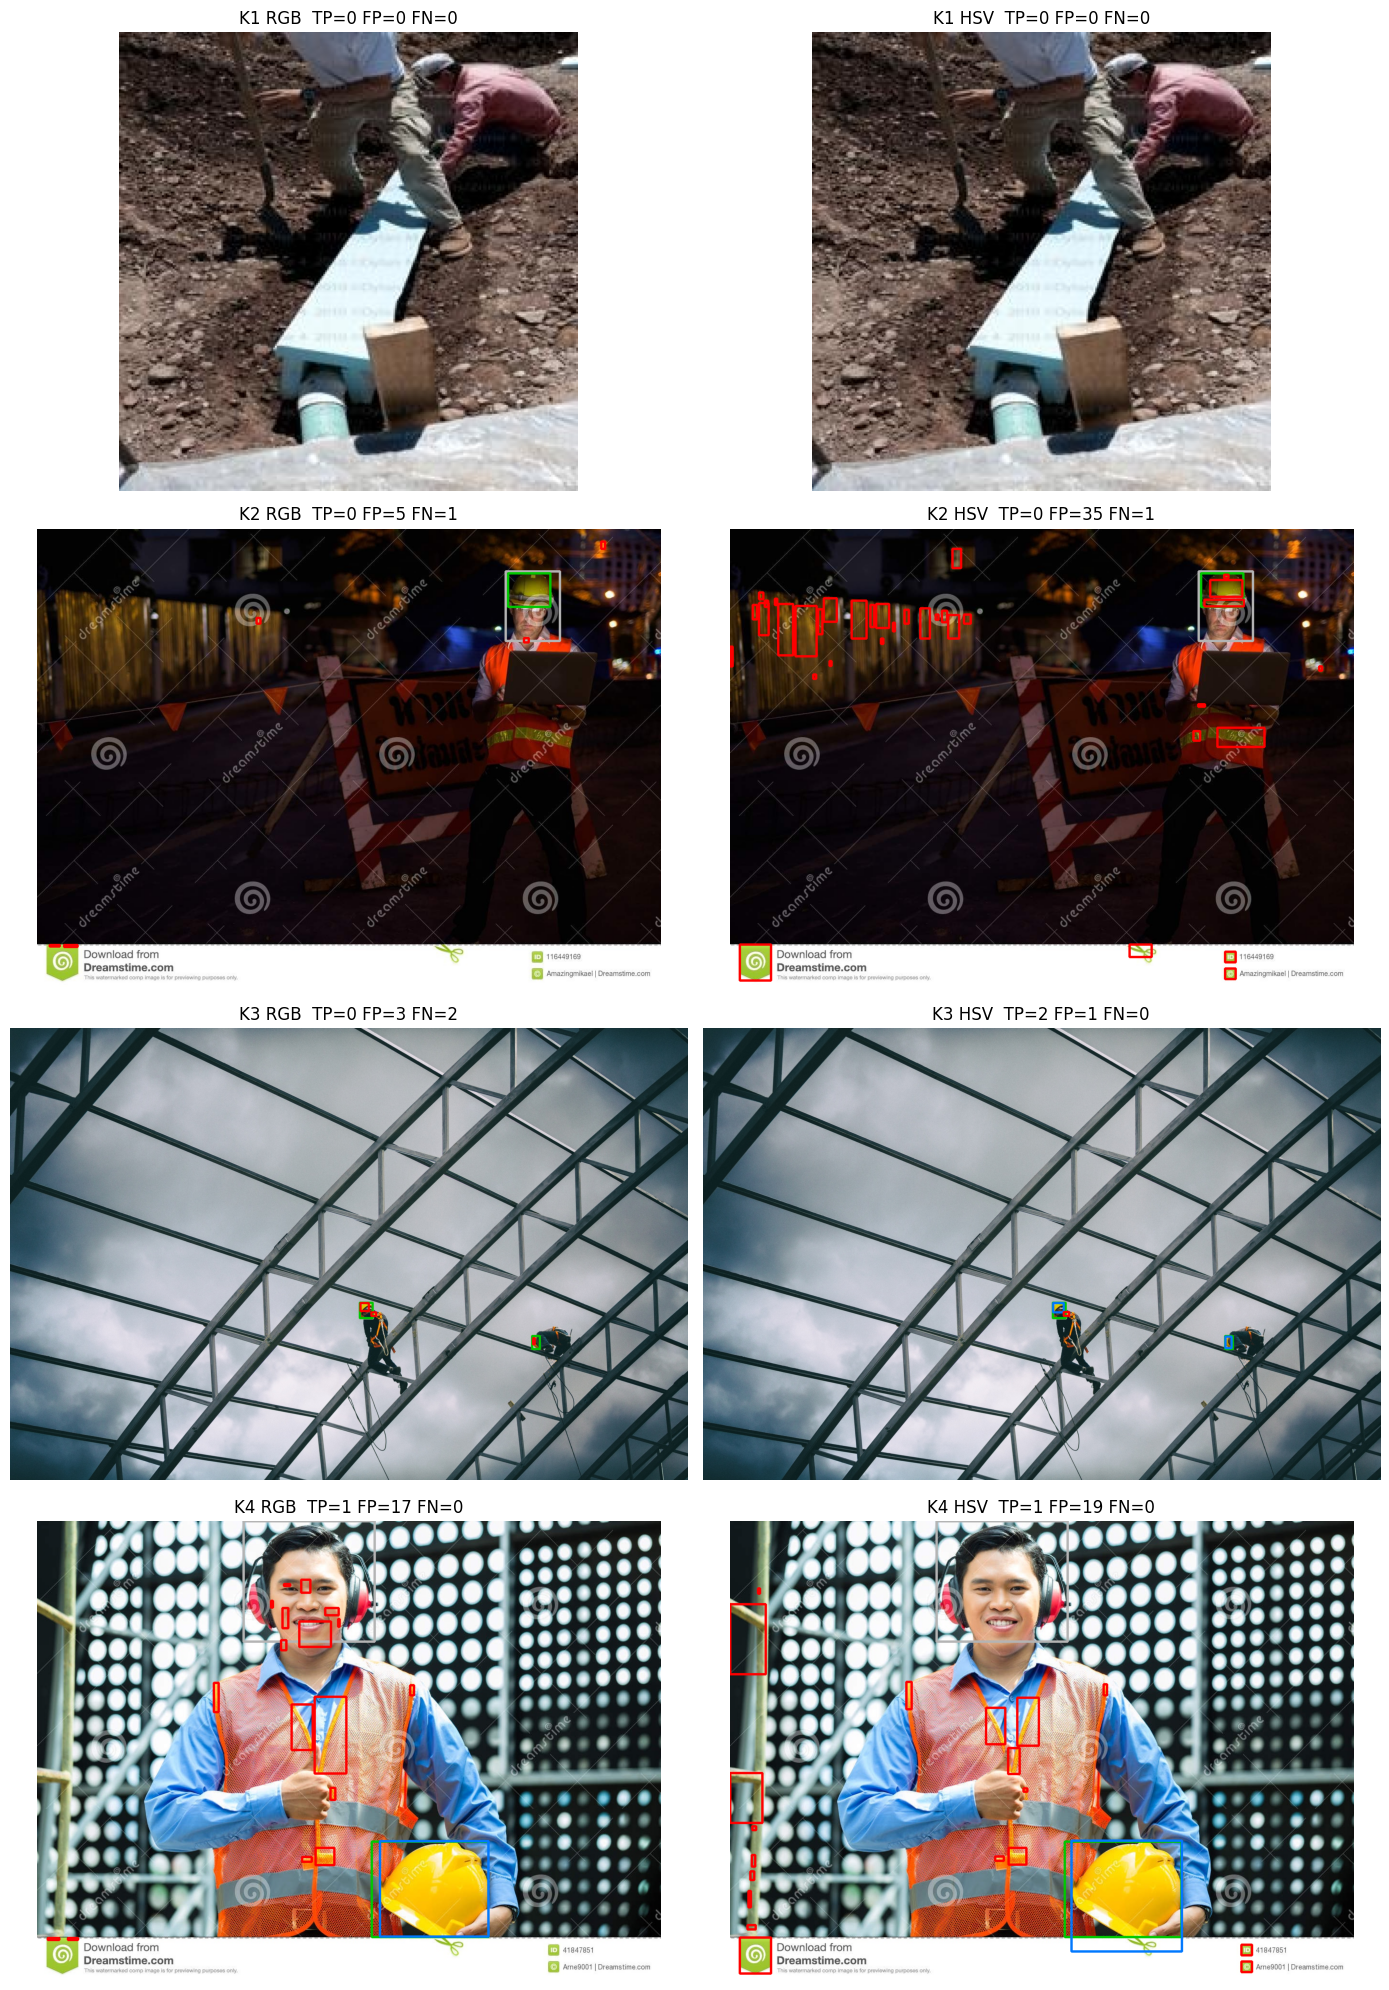

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(14, 20))
for row_axes, image_id in zip(axes, ["K1", "K2", "K3", "K4"]):
    for ax, method in zip(row_axes, ["rgb", "hsv"]):
        image, comps, rec, ev = control_store[(image_id, method)]
        canvas = draw_boxes(image, comps, rec["helmet_boxes"], ev, rec.get("head_roi"))
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{image_id} {method.upper()}  TP={ev['tp']} FP={ev['fp']} FN={ev['fn']}")
        ax.axis("off")
plt.tight_layout()
plt.show()

### Kaçırma örneği yakından: K2 (gece) ve K3 (uzak)

Kutular gerçek baretin üzerine düşse de IoU eşiğini geçemiyor: baret maskede parçalara ayrılıyor veya yalnızca bir kısmı renk aralığına giriyor.

K2 RGB GT [981, 94, 1070, 165]: üstüne düşen kutular (IoU, kutu) -> yok
K2 HSV GT [981, 94, 1070, 165]: üstüne düşen kutular (IoU, kutu) -> [(0.39, [1000, 108, 1068, 144]), (0.19, [988, 149, 1071, 164]), (0.01, [1029, 97, 1039, 105])]
K3 RGB GT [1094, 859, 1135, 908]: üstüne düşen kutular (IoU, kutu) -> [(0.35, [1096, 860, 1123, 886]), (0.03, [1130, 889, 1146, 901])]
K3 RGB GT [1633, 963, 1658, 1005]: üstüne düşen kutular (IoU, kutu) -> [(0.11, [1636, 970, 1642, 990])]
K3 HSV GT [1094, 859, 1135, 908]: üstüne düşen kutular (IoU, kutu) -> [(0.51, [1095, 860, 1129, 890]), (0.04, [1128, 888, 1146, 901])]
K3 HSV GT [1633, 963, 1658, 1005]: üstüne düşen kutular (IoU, kutu) -> [(0.7, [1634, 965, 1654, 1002])]


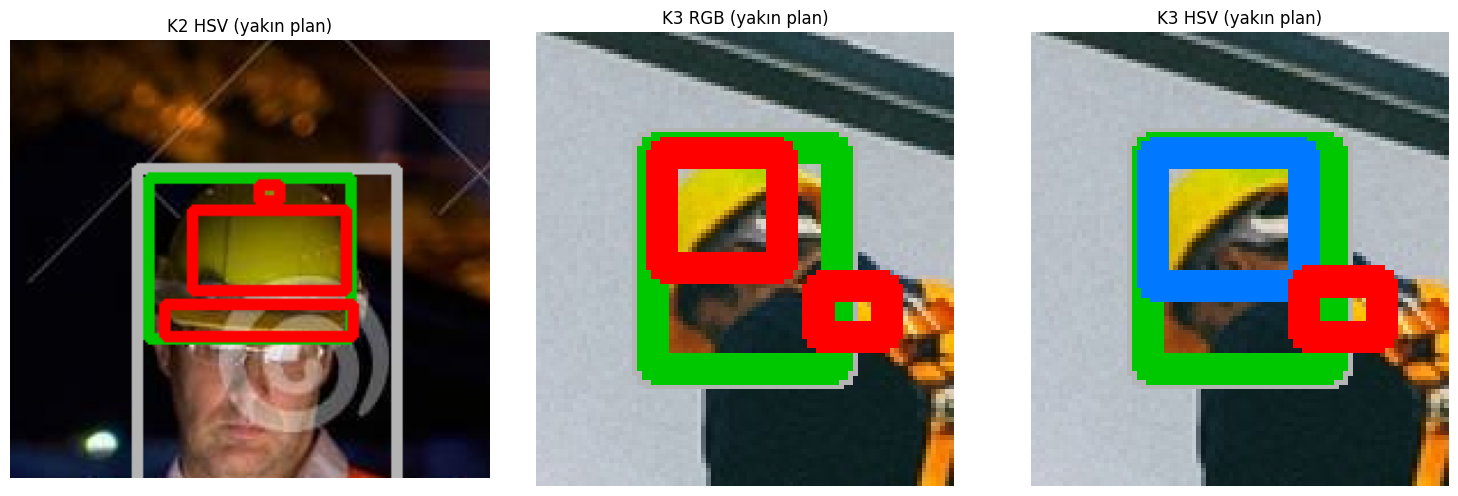

In [10]:
for image_id in ("K2", "K3"):
    for method in ("rgb", "hsv"):
        _, comps, rec, ev = control_store[(image_id, method)]
        for gt in rec["helmet_boxes"]:
            near = sorted(((round(iou(c["box"], gt), 2), c["box"]) for c in comps if iou(c["box"], gt) > 0), reverse=True)
            print(f"{image_id} {method.upper()} GT {gt}: üstüne düşen kutular (IoU, kutu) -> {near or 'yok'}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
crops = [("K2", "hsv", 0, 60), ("K3", "rgb", 0, 25), ("K3", "hsv", 0, 25)]
for ax, (image_id, method, gt_index, pad) in zip(axes, crops):
    image, comps, rec, ev = control_store[(image_id, method)]
    canvas = draw_boxes(image, comps, rec["helmet_boxes"], ev, rec.get("head_roi"))
    x1, y1, x2, y2 = rec["helmet_boxes"][gt_index]
    crop = canvas[max(0, y1 - pad):y2 + pad, max(0, x1 - pad):x2 + pad]
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{image_id} {method.upper()} (yakın plan)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Hata analizi

**Yanlış alarm (FP) — K4, RGB ve HSV.** Baret IoU 0.92 (RGB) ile doğru bulundu, ancak yelek, kordon, yüzdeki ten rengi ve filigran logosu da kutu üretti (RGB 17, HSV 19 FP). *Neden:* yöntem yalnızca renge bakıyor; aynı renk aralığındaki her bölge aday oluyor. *Sonraki kontrol:* kutulara şekil ölçütü (en-boy oranı, doluluk) veya baş ROI çevresi koşulu ekleyip aynı görüntüde yeniden ölçmek.

**Kaçırma (FN) — K2, gece.** RGB'de baret pikselleri aralığın altında kaldı (kutu yok). HSV bareti gördü ama üst kısım ve siperlik iki ayrı lekeye bölündü (IoU 0.39 ve 0.19), ikisi de eşiğin altında kaldı. Aynı görüntüde sokak ışığıyla sarılaşan çit 35 FP üretti. *Neden:* düşük ışıkta renk değerleri kayıyor ve tek leke = tek nesne varsayımı bozuluyor. *Sonraki kontrol:* birbirine yakın lekeleri birleştirme kuralını geliştirme setinde tanımlayıp K2'yi yeniden ölçmek.

**Sınırda doğru — K3, HSV.** İki uzak baret de bulundu (IoU 0.51 ve 0.70); ilki eşiğin hemen üstünde. Küçük nesnelerde birkaç piksellik kayma TP'yi FN'ye çevirebilir. RGB aynı baretleri yalnızca kısmen yakaladı (IoU 0.35 ve 0.11 → 2 FN).

**K4 ve "başta mı?" sorusu (S3).** K4'te baret kutusu doğru bulundu ama baret elde tutuluyor; doğru sınıf *baret var, başta değil*. Kutu bulmak, baretin başta olduğunu göstermez.

**Veri sınırlılığı.** K2 ve K4'teki Dreamstime filigranı ve logo da FP üretiyor; bu yöntemden değil görüntü kaynağından gelen bir hatadır. Altı görüntülük bu deney gerçek saha güvenilirliği iddiası taşımaz.

## 9. Tahmin ile sonucun karşılaştırması

| Tahmin | Sonuç |
|---|---|
| Çok sayıda FP, özellikle RGB'de | Doğru: çok FP var; ancak toplamda HSV daha fazla FP üretti (55'e karşı 25), çoğu K2 gece görüntüsünden |
| K4'te baret TP, ama başta değil | Doğru: RGB IoU 0.92, HSV IoU 0.82 |
| K2'deki karanlık baret FN | Doğru: iki yöntemde de FN |
| K3'teki küçük baretler FN | RGB'de doğru (2 FN); HSV'de yanlış — iki baret de TP (biri sınırda) |